#1. Problem Definition and Data Preparation

Project title: Comparative Evaluation of MLP and RBF Neural Networks for Dry Bean Classification

Problem: Predict the variety of a dry bean from 16 numerical morphological measurements

Intended user: Agricultural researchers or quality-control personnel who need to identify bean varieties from measured shape characteristics

Prediction target: One of seven bean varieties (BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA)

Unit of observation: One bean sample represented by 16 extracted morphological features.

Practical value: Investigate whether automated prediction from measured features can assist bean-variety identification. A possible decision-support application is sorting or quality inspection, but deployment performance has not been established.

Data source and provenance: UCI Machine Learning Repository, Dry Bean Dataset (ID 602), 13,611 original observations, 16 numeric features and 7 classes.

Dataset access and licence: CC BY 4.0. UCI dataset page.

Original dataset authors: Koklu and Ozkan (2020). UCI DOI: 10.24432/C50S4B.




Ethical and practical considerations:
Errors in prediction can lead to misidentification of varieties. The results of the published data set are not necessarily indicative of the reliability of the data when collected under new conditions. The system should not be considered as validated for use in the real world.



Dataset: UCI Dry Bean (ID 602), https://archive.ics.uci.edu/dataset/602/dry+bean. Koklu & Ozkan (2020), DOI 10.24432/C50S4B, CC BY 4.0. 13,611 observations, 16 numeric features, seven target classes (verify actual loaded counts in the output)

In [1]:
%pip -q install ucimlrepo==0.0.7

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
BASE = Path('/content/drive/MyDrive/ANN_DryBean_CW1')
DATA_DIR = BASE / 'data'
FIG_DIR = BASE / 'figures'
ARTIFACT_DIR = BASE / 'artifacts'
for folder in (BASE, DATA_DIR, FIG_DIR, ARTIFACT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Project files saved to:', BASE)

Mounted at /content/drive
Project files saved to: /content/drive/MyDrive/ANN_DryBean_CW1


#2. Download the original data from UCI

Feature - measurement for model

Target - The answer the model needs to predict

Row/observation - bean sample

In [2]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

bean_data = fetch_ucirepo(id=602)
X_raw = bean_data.data.features.copy()
y_raw = bean_data.data.targets.iloc[:, 0].copy()

raw_df = X_raw.copy()
raw_df['Class'] = y_raw.astype('string').str.strip()
feature_cols = list(X_raw.columns)

print('Original dataset shape (rows, columns):', raw_df.shape)
print('Number of features:', len(feature_cols))
print('Target classes:', sorted(raw_df['Class'].dropna().unique().tolist()))
print('First five observations:')
display(raw_df.head())
raw_df.to_csv(DATA_DIR / 'dry_bean_original.csv', index=True, index_label='original_row_id')
print('Saved original data to:', DATA_DIR / 'dry_bean_original.csv')

Original dataset shape (rows, columns): (13611, 17)
Number of features: 16
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
First five observations:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Saved original data to: /content/drive/MyDrive/ANN_DryBean_CW1/data/dry_bean_original.csv


#3. Basic data audit: missing, duplicates, classes, feature statistics


In [3]:
print('Total rows:', len(raw_df))
print('Number of input features:', len(feature_cols))
print('Missing values in whole dataset:', int(raw_df.isna().sum().sum()))
print('Exact duplicate rows:', int(raw_df.duplicated().sum()))
print('\nMissing values by column:')
display(raw_df.isna().sum().to_frame('missing_count'))
print('\nBean class counts:')
display(raw_df['Class'].value_counts().rename_axis('Class').to_frame('count'))
print('\nNumerical feature statistics:')
display(raw_df[feature_cols].describe().T)
print('\nNon-positive values in Area / Perimeter (if present):')
for name in ('Area', 'Perimeter'):
    if name in raw_df.columns:
        print(name, int((raw_df[name] <= 0).sum()))

Total rows: 13611
Number of input features: 16
Missing values in whole dataset: 0
Exact duplicate rows: 68

Missing values by column:


,missing_count
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0



Bean class counts:


,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677



Non-positive values in Area / Perimeter (if present):
Area 0
Perimeter 0


##T1b - Data audit: observations and decisions

The original data set has 13611 observations and 16 numeric variables. The audit found 0 missing cells and 68 exact duplicate rows. There are no non-positive numbers in the Area and Perimeter columns. Another check later on also revealed 0 cases with the same features but different class labels, for which the exact duplicates were excluded prior to splitting, resulting in 13543 observations. This decreases the chances of having the same example in the training data and the test data.

The frequencies of the seven classes are not equal (3546 for DERMASON and 522 for BOMBAY in the original data). So, stratified partitioning is applied and macro-F1 is considered as an important primary metric in addition to accuracy and per-class recall. There are also different numerical ranges of the features which encourages training only standardization. Values that could be extreme will be checked, but not removed

#4. check contradictory examples and clean duplicate observations

In [4]:
# Same feature vector but contradictory bean labels?
conflicting_vectors = raw_df.groupby(feature_cols, dropna=False)['Class'].nunique(dropna=False)
num_conflicting_vectors = int((conflicting_vectors > 1).sum())
print('Feature vectors with conflicting target labels:', num_conflicting_vectors)
if num_conflicting_vectors > 0:
    raise ValueError('Conflicting feature labels found: inspect these before removing duplicates or splitting.')

clean_df = raw_df.drop_duplicates().copy()  # preserve original row index
removed_duplicates = len(raw_df) - len(clean_df)
print('Exact duplicate observations removed:', removed_duplicates)
print('Cleaned dataset size:', clean_df.shape)
assert clean_df[feature_cols].notna().all().all(), 'Missing features need explicit treatment.'
assert clean_df['Class'].notna().all(), 'Missing class labels need explicit treatment.'
clean_df.to_csv(DATA_DIR / 'dry_bean_clean.csv', index=True, index_label='original_row_id')

Feature vectors with conflicting target labels: 0
Exact duplicate observations removed: 68
Cleaned dataset size: (13543, 17)


#5. Freeze train/validation/test splits

A stratified split of 70/15/15 was chosen to ensure sufficient observations for training the neural networks and leave out some observations for model selection and final testing. Previously, exact duplicates were removed prior to splitting. The same saved partitions will be reused by every model. No identifiers were included for the specimens or groups and any dependencies between observations collected cannot be independently verified

In [5]:
from sklearn.model_selection import train_test_split

SPLIT_SEED = 42
train_ids, remaining_ids = train_test_split(
    clean_df.index.to_numpy(), test_size=0.30,
    random_state=SPLIT_SEED, stratify=clean_df['Class']
)
val_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.50,
    random_state=SPLIT_SEED,
    stratify=clean_df.loc[remaining_ids, 'Class']
)

train_df = clean_df.loc[train_ids].copy()
val_df = clean_df.loc[val_ids].copy()
test_df = clean_df.loc[test_ids].copy()

assert len(set(train_ids) & set(val_ids)) == 0
assert len(set(train_ids) & set(test_ids)) == 0
assert len(set(val_ids) & set(test_ids)) == 0
assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)

for name, frame in [('Train',train_df),('Validation',val_df),('Test',test_df)]:
    print(f'{name}: {len(frame)} samples ({100*len(frame)/len(clean_df):.2f}%)')
    print(frame['Class'].value_counts(normalize=True).round(3).to_dict())

Train: 9480 samples (70.00%)
{'DERMASON': 0.262, 'SIRA': 0.195, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.12, 'BARBUNYA': 0.098, 'BOMBAY': 0.039}
Validation: 2031 samples (15.00%)
{'DERMASON': 0.262, 'SIRA': 0.194, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.12, 'BARBUNYA': 0.098, 'BOMBAY': 0.038}
Test: 2032 samples (15.00%)
{'DERMASON': 0.262, 'SIRA': 0.195, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.121, 'BARBUNYA': 0.097, 'BOMBAY': 0.038}


#6. EDA plot - class distribution (Train only)

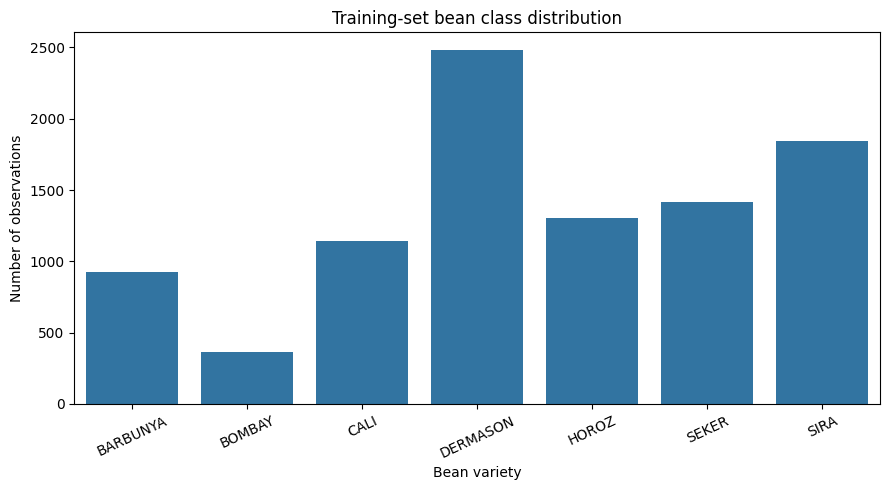

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.countplot(data=train_df, x='Class', order=sorted(train_df['Class'].unique()))
plt.title('Training-set bean class distribution')
plt.xlabel('Bean variety')
plt.ylabel('Number of observations')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure1_training_class_distribution.png', dpi=180)
plt.show()

Figure 1 - The training set class distribution is imbalanced: DERMASON is the most frequent variety and BOMBAY the least frequent. The overall accuracy could mask poor performance for smaller classes. So plan to report macro-F1, accuracy, a confusion matrix and class-level precision/recall/F1 in T4.Class proportions are fairly similar between train, validation and test partitions.

## Bean ares by class (Train only)

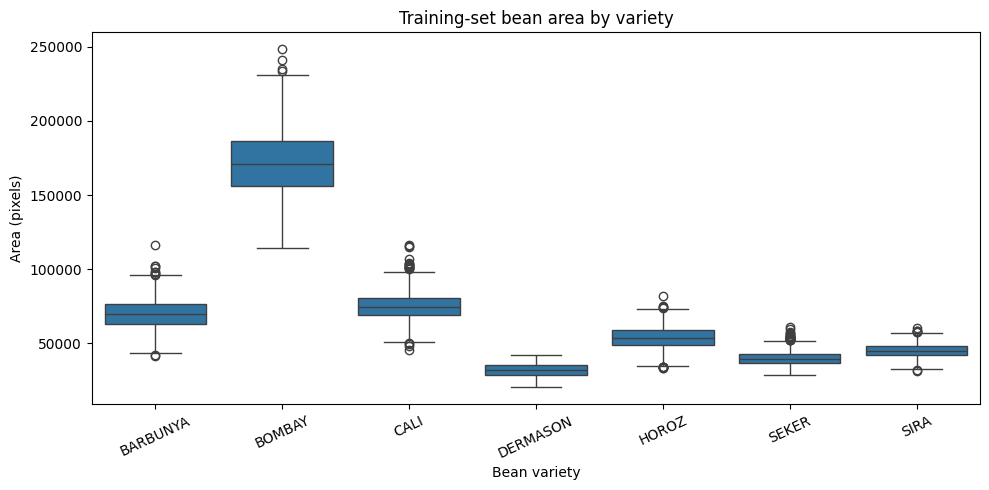

In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df, x='Class', y='Area', order=sorted(train_df['Class'].unique()))
plt.title('Training-set bean area by variety')
plt.xlabel('Bean variety')
plt.ylabel('Area (pixels)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure2_area_by_class.png', dpi=180)
plt.show()

Figure 2 - The Area measurement varies considerably among bean varieties: BOMBAY shows significantly higher measurement than most of the other varieties. There are points outside the boxplot whiskers in a few classes. These are potential outlier data points but not necessarily incorrect records. They are retained unless a defensible reason for removal in terms of data quality is identified. Area may be used for classification but it is not likely to be sufficient for distinguishing all the classes


## Feature correlation (Train only)

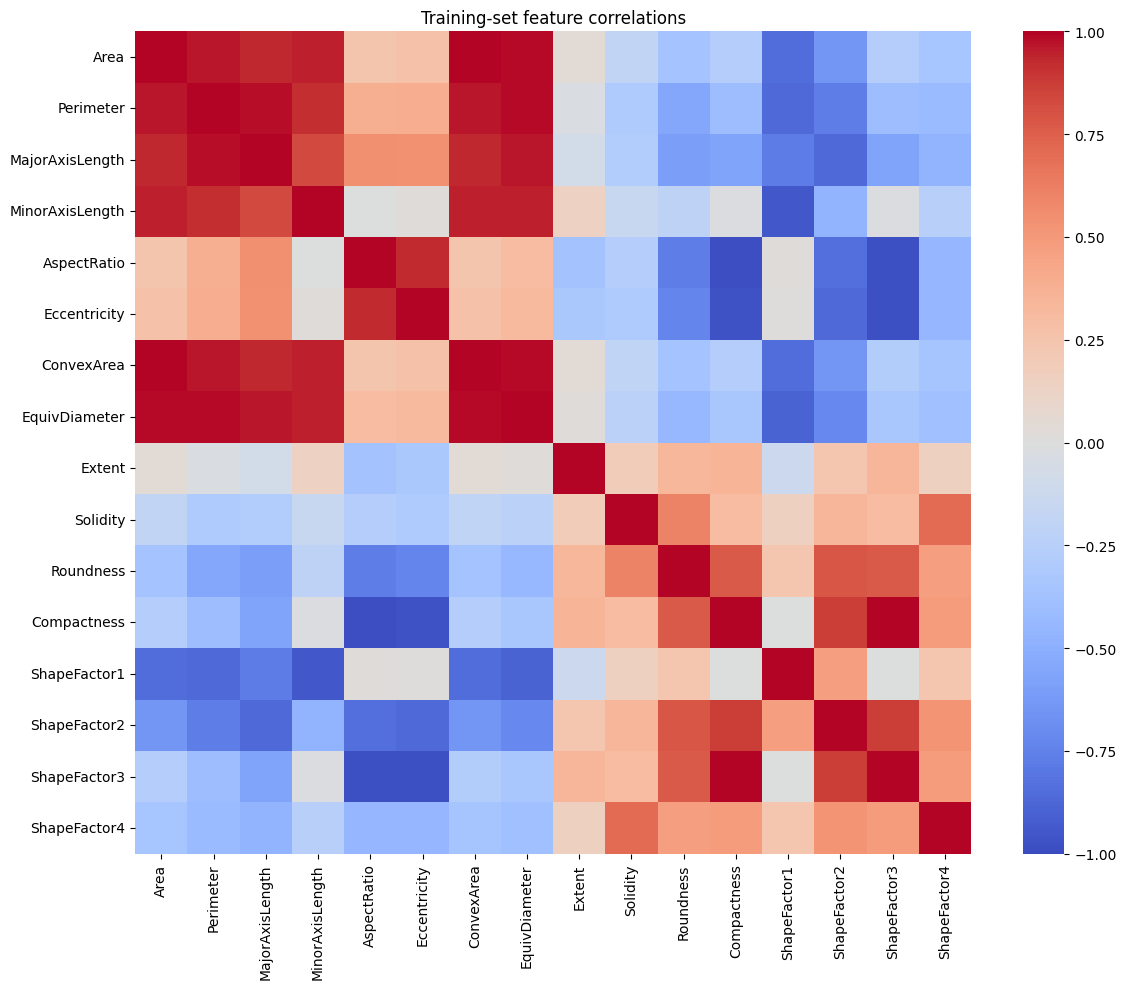

In [8]:
plt.figure(figsize=(12, 10))
sns.heatmap(train_df[feature_cols].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Training-set feature correlations')
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure3_training_feature_correlations.png', dpi=180)
plt.show()

Figure 3 - The heatmap shows strong positive correlations among size related features such as Area, ConvexArea and EquivDiameter.It also provides highly related shape descriptors such as Compactness and ShapeFactor3. These relationships show potential for redundant information but correlation alone does not provide information about which inputs should be eliminated. All 16 inputs are retained for the initial fair comparison and may be justified and evaluated as optional feature reduction experiments later

#7. Fit preprocessing on training data only

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
label_encoder = LabelEncoder()

X_train = preprocessor.fit_transform(train_df[feature_cols]).astype(np.float32)
X_val = preprocessor.transform(val_df[feature_cols]).astype(np.float32)
X_test = preprocessor.transform(test_df[feature_cols]).astype(np.float32)
y_train = label_encoder.fit_transform(train_df['Class'])
y_val = label_encoder.transform(val_df['Class'])
y_test = label_encoder.transform(test_df['Class'])

print('X_train / y_train:', X_train.shape, y_train.shape)
print('X_val / y_val:', X_val.shape, y_val.shape)
print('X_test / y_test:', X_test.shape, y_test.shape)
print('Class mapping:', dict(enumerate(label_encoder.classes_.tolist())))
print('Training-set mean after scaling (first 3 features):', np.round(X_train.mean(axis=0)[:3], 3))

X_train / y_train: (9480, 16) (9480,)
X_val / y_val: (2031, 16) (2031,)
X_test / y_test: (2032, 16) (2032,)
Class mapping: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Training-set mean after scaling (first 3 features): [ 0.  0. -0.]


##Why the preprocessing is leakage safe

After removing exact duplicates, the stratified 70/15/15 partition is fixed with seed 42 and its original row indices are saved. This ratio ensures that most observations are used for training and also creates a separate validation set and final test set. These same splits will be used for all models. Model features do not include the target (Class) or saved row identifiers. The median imputer and standard scaler are only trained on the training data and then transformed on the validation and test data with the parameters learned in the training phase. The target encoder is also trained on the training labels. No augmentation is used. The test set is not used for tuning, selection, or debugging of model performance. Independence between the different observed beans is limited as specimen/group identifiers are not available

In [11]:
# Additional T1 verification checks

assert 'Class' not in feature_cols
assert 'original_row_id' not in feature_cols

# Each partition must contain every target class.
expected_classes = set(range(7))

for name, X, y in [
    ('Train', X_train, y_train),
    ('Validation', X_val, y_val),
    ('Test', X_test, y_test)
]:
    assert X.shape[1] == 16
    assert np.isfinite(X).all()
    assert set(np.unique(y)) == expected_classes
    print(f'{name}: shape, finite values and classes OK')

# No repeated feature vector remains after cleaning.
assert not clean_df.duplicated(subset=feature_cols).any()

print('Additional T1 verification checks passed.')

Train: shape, finite values and classes OK
Validation: shape, finite values and classes OK
Test: shape, finite values and classes OK
Additional T1 verification checks passed.


#8. save exact split IDs, settings, processed data and evidence

In [10]:
import json, sys, platform
import joblib
import sklearn
import ucimlrepo

np.savez_compressed(
    DATA_DIR / 'split_original_row_ids.npz',
    train_ids=train_ids.astype(np.int64),
    val_ids=val_ids.astype(np.int64),
    test_ids=test_ids.astype(np.int64)
)
np.savez_compressed(
    DATA_DIR / 't1_processed_splits.npz',
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)
joblib.dump(preprocessor, ARTIFACT_DIR / 't1_train_fitted_preprocessor.joblib')
joblib.dump(label_encoder, ARTIFACT_DIR / 't1_label_encoder.joblib')

summary = {
    'dataset_name': 'UCI Dry Bean',
    'dataset_uci_id': 602,
    'dataset_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean',
    'dataset_licence': 'CC BY 4.0',
    'raw_rows': int(len(raw_df)),
    'features': feature_cols,
    'total_missing_cells': int(raw_df.isna().sum().sum()),
    'exact_duplicate_rows_removed': int(removed_duplicates),
    'conflicting_feature_vectors': int(num_conflicting_vectors),
    'clean_rows': int(len(clean_df)),
    'class_counts_original': {str(k):int(v) for k,v in raw_df['Class'].value_counts().items()},
    'split_seed': SPLIT_SEED,
    'split_counts': {'train':len(train_df),'validation':len(val_df),'test':len(test_df)},
    'split_strategy': 'stratified random 70/15/15 after exact duplicate removal',
    'preprocessing': 'training-fitted median imputer and standard scaler',
    'target_encoding': {str(name):int(i) for i,name in enumerate(label_encoder.classes_)},
    'versions': {
        'python':sys.version.split()[0],
        'pandas':pd.__version__,
        'numpy':np.__version__,
        'scikit_learn':sklearn.__version__,
        'ucimlrepo': '0.0.7',
        'platform':platform.platform()
    }
}
with open(ARTIFACT_DIR / 't1_run_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved T1 artifacts to Drive:', BASE)
print('T1 output files:')
for item in sorted(BASE.rglob('*')):
    if item.is_file():
        print('-', item.relative_to(BASE))

Saved T1 artifacts to Drive: /content/drive/MyDrive/ANN_DryBean_CW1
T1 output files:
- artifacts/t1_label_encoder.joblib
- artifacts/t1_run_summary.json
- artifacts/t1_train_fitted_preprocessor.joblib
- data/dry_bean_clean.csv
- data/dry_bean_original.csv
- data/split_original_row_ids.npz
- data/t1_processed_splits.npz
- figures/T1_Figure1_training_class_distribution.png
- figures/T1_Figure2_area_by_class.png
- figures/T1_Figure3_training_feature_correlations.png
